**Importing dataset from kaggle**

In [1]:
!pip install -q kaggle

Accessing the credentials

In [2]:
from google.colab import userdata
import os

os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

from kaggle.api.kaggle_api_extended import KaggleApi
api = KaggleApi()
api.authenticate()

Downloading the dataset

In [3]:
api.dataset_download_files("ankurzing/sentiment-analysis-for-financial-news", path="./", unzip=True)

Dataset URL: https://www.kaggle.com/datasets/ankurzing/sentiment-analysis-for-financial-news


In [4]:
import pandas as pd

Reading the data

In [5]:
df = pd.read_csv('all-data.csv', header=None, encoding='latin')
df.columns = ['sentiment', 'text']

In [6]:
df.head()

,sentiment,text
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


**Data Exploration & Analysis**

In [7]:
df.shape

(4846, 2)

In [8]:
df.isnull().sum()

,0
sentiment,0
text,0


In [9]:
df.duplicated().sum()

np.int64(6)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   sentiment  4846 non-null   object
 1   text       4846 non-null   object
dtypes: object(2)
memory usage: 75.8+ KB


In [11]:
df['sentiment'].value_counts()

,count
sentiment,
neutral,2879
positive,1363
negative,604


Let's plot the above sentiment value counts

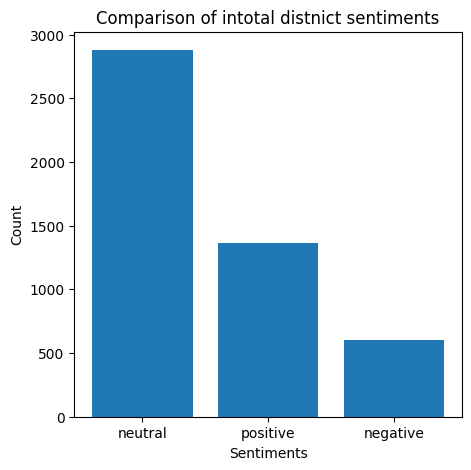

In [12]:
import matplotlib.pyplot as plt

counts = df['sentiment'].value_counts()
# This is a series data of different type of sentiments and their counts

plt.figure(figsize = [5,5])
# figsize creates the image with the required size (inch*inch)
plt.bar(counts.index,counts.values)
# counts is a series so we need to access them using .index and .values
plt.title("Comparison of intotal distnict sentiments")
plt.xlabel("Sentiments")
plt.ylabel("Count")
plt.show()

Word visualization according to their frequency (speartely for each category of sentiment). This helps in getting to know what words are used more/relate to particular sentiment
And we relaise that negative sentimnets are less compare to others

In [13]:
from wordcloud import WordCloud

def forming_wordcloud(text,title):
  word_cloud = WordCloud(width = 800, height = 800, background_color = 'white').generate(' '.join(text))
  plt.figure()
  plt.imshow(word_cloud, interpolation = 'bilinear')
  plt.axis("off")
  plt.title(title)
  plt.show()

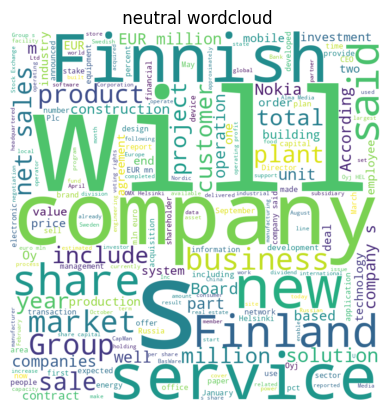

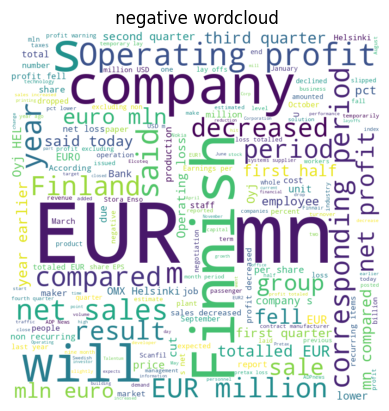

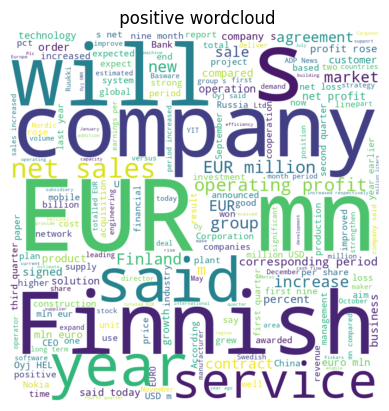

In [14]:
for sentiment in df['sentiment'].unique():
  forming_wordcloud(df[df['sentiment'] == sentiment]['text'], f" {sentiment} wordcloud")

*   Not much intution can be made from the above visualization.
*   Now let's compare the overall text lengths.

In [15]:
df['len_of_sentence'] = df['text'].apply(len)

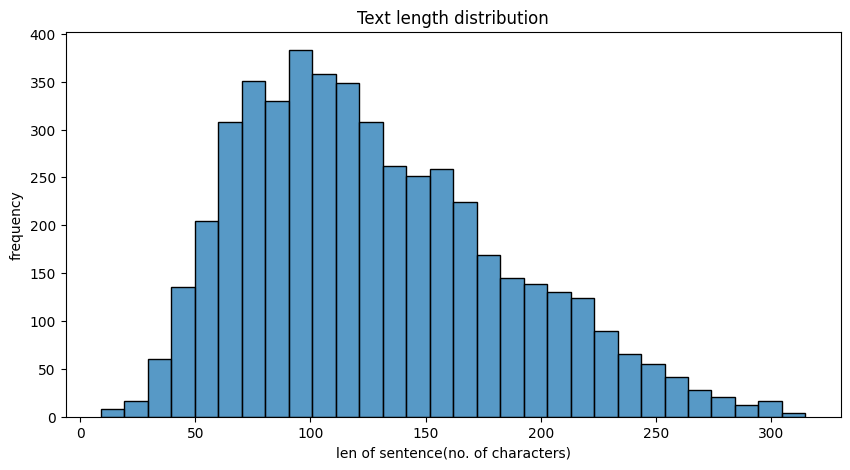

In [16]:
import seaborn as sns
#matplotlib doesn't have histplot so we are using seaborn library (which is an advanced library)
plt.figure(figsize = [10,5])
sns.histplot(df['len_of_sentence'],bins = 30)
plt.xlabel("len of sentence(no. of characters)")
plt.ylabel('frequency')
plt.title("Text length distribution")
plt.show()

* **Visual Representation:** The graph uses a histogram to show the frequency of different text lengths.
*  **Frequency Range:** The y-axis ranges from 0 to 400, indicating a wide variability in text lengths within the dataset.
*   **Contextual Insight:** The distribution helps in understanding the details of sentences and useful for quality control and process improvement.



In [17]:
df['len_of_sentence'].describe()

,len_of_sentence
count,4846.000000
mean,128.132068
std,56.526180
min,9.000000
25%,84.000000
50%,119.000000
75%,163.000000
max,315.000000


So the avg length of the sentence is 128 words

**Data Preprocessing**

In [18]:
df.head()

,sentiment,text,len_of_sentence
0,neutral,"According to Gran , the company has no plans t...",127
1,neutral,Technopolis plans to develop in stages an area...,190
2,negative,The international electronic industry company ...,228
3,positive,With the new production plant the company woul...,206
4,positive,According to the company 's updated strategy f...,203


In [19]:
import random
import torch
import numpy as np

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [20]:
from bs4 import BeautifulSoup
# beautifulsoap is for html parsing
import re
# re is regex and regex is for searching, matching, extracting, replacing, and validating text based on patterns.
import nltk
from nltk.corpus import stopwords, wordnet
#we first import the stopwords modules, which knows how to access the data sets
nltk.download('stopwords')
#then we are downloading the stopwords dataset from NLTK servers to our local database
stop_words = set(stopwords.words('english'))

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [21]:
def text_preprocessing(text):
  text = BeautifulSoup(text,"html.parser").get_text()   #removes HTML tags
  text = re.sub(r"https\S+|www\S+",'',text)
  #removes/subtracts URLs untill there is a whitespace character (S+ represnts to subtract all the following characters after https until there is non-white space)
  text = re.sub(r"[^a-zA-Z0-9\s]",'',text)
  #removes charcters other than alphabets and digits
  text = text.lower()
  #converting to lowercase
  text = ' '.join(word for word in text.split() if word not in stop_words)
  return text

We need to encode the sentiments to categorical values as sentiment is a target variable so categorical encoding is good to go.

In [22]:
from sklearn.preprocessing import LabelEncoder
# when are going into machine learning model so we should use scikit learn modules
encoder = LabelEncoder()
df['sentiment'] = encoder.fit_transform(df['sentiment'])

My goal is to separate the dataset into train and temp.
Then I will be splitting the temp into valdiation and test datasets

In [23]:
from sklearn.model_selection import train_test_split
train_df,temp_df = train_test_split(df,test_size = 0.3, random_state = 42, stratify = df['sentiment'], shuffle = True)
# stratify makes sure that the ratios of each type of sentiment in the train_df and temp_df remains same
#shuffle is for shuffling the dataset before splitting and random seed(42) applies only during the split

In [10]:
train_df

NameError: name 'train_df' is not defined

In [25]:
temp_df

,sentiment,text,len_of_sentence
4082,2,The groups 's turnover for the full fiscal yea...,117
4338,1,The company says it is difficult to estimate t...,91
1078,2,TeliaSonera is the leading telecommunications ...,88
3775,1,The business development initiatives in North ...,83
4594,0,"Operating loss totalled EUR 0.9 mn , down from...",71
...,...,...,...
4726,0,"Commission income decreased to EUR 3.8 mn , co...",97
2328,1,28 January 2011 - Finnish technology center op...,193
2587,1,The Board of Directors was authorized to decid...,83
4694,0,Net sales decreased to EUR 91.6 mn from EUR 10...,87


In [26]:
val_df,test_df = train_test_split(temp_df,test_size = 0.5, random_state = 42, stratify = temp_df['sentiment'], shuffle = True)

In [27]:
val_df

,sentiment,text,len_of_sentence
3765,1,The Americas represents 25 % of Gemalto 's bil...,126
2372,2,Finnish food industry companies HK Ruokatalo a...,136
3987,0,The personnel reductions will primarily affect...,176
2077,1,According to Scanfil 's President Harri Takane...,144
915,1,To choose BasWare as the tools for our Financi...,194
...,...,...,...
3848,1,The facility consists of a seven year bullet t...,151
2271,2,"Cargotec Corporation , Press Release , August ...",241
4023,1,He said : `` It is for sale again and we will ...,72
1590,1,RusHydro has an agreement to transfer its stak...,115


In [28]:
test_df

,sentiment,text,len_of_sentence
3216,1,The contract covers the supply of temporary he...,123
4196,0,He said he has been losing five families a mon...,117
2105,1,Finnish software company QPR Software Plc ( OM...,191
431,1,"In April 2005 , Neste separated from its paren...",140
909,2,The parties have also agreed on options that a...,140
...,...,...,...
2076,2,According to Olvi 's Managing Director Lasse A...,137
3406,1,The volume of investments in the two phases of...,104
4323,1,Information system supplier Sentera -- up 24.5...,208
578,1,"Helsinki on October 22 , 2008 SSH COMMUNICATIO...",217


**Downloading the Pre Trained Tokenizer & Model**

Teacher Model: FinBERT Model

In [29]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
#Pretrained Teacher Model & Tokenizer
import torch


teacher_model_name = "ProsusAI/finbert"

tokenizer = AutoTokenizer.from_pretrained(teacher_model_name)
#This line downloads the tokens of the pretrained teacher model

teacher_model = AutoModelForSequenceClassification.from_pretrained(teacher_model_name)
#This loads the FinBERT model/complete architecture

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# Determining device for the model

teacher_model.to(device)
# Moving model to GPU (if available)

teacher_model.eval()
# Teacher model will only be used for inference/evaluation

config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/438M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/438M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [30]:
print(teacher_model)

BertForSequenceClassification(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12,

In [31]:
from transformers import AutoModel

student_model_name = "distilbert-base-uncased"
#This model has only 6 transformer layer whereas teacher model has 12 transformer layers
#and here uncased means this model unclases every alphabet into small letters.

student_model = AutoModel.from_pretrained(student_model_name)
#This only loads the encoder part and after this I am going to define the customBERT model
#which places our own dense layers to make the sentiment prediction.

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.weight  | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


In [32]:
print(student_model)

DistilBertModel(
  (embeddings): Embeddings(
    (word_embeddings): Embedding(30522, 768, padding_idx=0)
    (position_embeddings): Embedding(512, 768)
    (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (transformer): Transformer(
    (layer): ModuleList(
      (0-5): 6 x TransformerBlock(
        (attention): DistilBertSelfAttention(
          (q_lin): Linear(in_features=768, out_features=768, bias=True)
          (k_lin): Linear(in_features=768, out_features=768, bias=True)
          (v_lin): Linear(in_features=768, out_features=768, bias=True)
          (out_lin): Linear(in_features=768, out_features=768, bias=True)
          (dropout): Dropout(p=0.1, inplace=False)
        )
        (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
        (ffn): FFN(
          (dropout): Dropout(p=0.1, inplace=False)
          (lin1): Linear(in_features=768, out_features=3072, bias=True)
          (lin2): L

In [33]:
X_train = tokenizer(train_df['text'].tolist(),max_length=128,padding=True,truncation=True,return_tensors="pt")
#Converts the words into token IDs

X_val = tokenizer(val_df['text'].tolist(),max_length=128,padding=True,truncation=True,return_tensors="pt")
#Converts the words into token IDs

y_train = train_df['sentiment'].values
y_val = val_df['sentiment'].values
#Converts the sentiment types into values of 0 --> negative ,1 --> neutral. ,2 --> positive

In [34]:
# Following is the custom BERT model which will be used on top of pretrained and imported student model
import torch
import torch.nn as nn

class CustomBERTModel(nn.Module):

    def __init__(self, student_model):
        super(CustomBERTModel, self).__init__()

        self.bert = student_model
        # DistilBERT encoder

        self.norm = nn.LayerNorm(768)
        # Layer Normalization

        # Fully Connected Layers
        self.dense1 = nn.Linear(768, 256)
        self.dropout1 = nn.Dropout(0.3)

        self.dense2 = nn.Linear(256, 128)
        self.dropout2 = nn.Dropout(0.2)

        self.dense3 = nn.Linear(128, 64)
        self.dropout3 = nn.Dropout(0.1)

        self.output_layer = nn.Linear(64, 3)

        self.relu = nn.ReLU()

    def forward(self, input_ids, attention_mask):

        outputs = self.bert(input_ids=input_ids,attention_mask=attention_mask)
        # DistilBERT output is the embeddings that are generated for the provided input

        x = outputs.last_hidden_state

        x = self.norm(x)
         # Layer Normalization

        mask = attention_mask.unsqueeze(-1).float()
        x = (x * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1e-9)

        # Dense Layers
        x = self.relu(self.dense1(x))
        x = self.dropout1(x)

        x = self.relu(self.dense2(x))
        x = self.dropout2(x)

        x = self.relu(self.dense3(x))
        x = self.dropout3(x)

        logits = self.output_layer(x)

        return logits

In [36]:
# Initializing CustomBERTModel with the base DistilBertModel
student_model = CustomBERTModel(student_model)
student_model.to(device)

CustomBERTModel(
  (bert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
          (ffn): FFN(
            (dropout): Dropout(p=0.1, inplace=False)
            (lin1): Linear

In [37]:
# print(next(student_model.parameters()).requires_grad)

In [38]:
import torch.nn.functional as F

def distillation_loss(student_logits,teacher_logits,labels,alpha=0.5,temperature=3.0):

    student_soft = F.log_softmax(student_logits / temperature, dim=1)
    teacher_soft = F.softmax(teacher_logits / temperature, dim=1)
    # student and teacher soft targets

    kl_loss = F.kl_div(student_soft,teacher_soft,reduction='batchmean') * (temperature ** 2)
    # KL Divergence Loss

    ce_loss = F.cross_entropy(student_logits,labels)
    # Hard Label Loss

    loss = alpha * kl_loss + (1 - alpha) * ce_loss
    # Combined Loss

    return loss

In [39]:
import torch.optim as optim

optimizer = optim.Adam(student_model.parameters(),lr=5e-5)
#importing adam optmizer

In [40]:
from torch.utils.data import TensorDataset, DataLoader

train_dataset = TensorDataset(X_train["input_ids"],X_train["attention_mask"],torch.tensor(y_train, dtype=torch.long))
#this step packages the tokenized data to feed the model

val_dataset = TensorDataset(X_val["input_ids"],X_val["attention_mask"],torch.tensor(y_val, dtype=torch.long))

train_loader = DataLoader(train_dataset,batch_size=32,shuffle=True)
#this step packs the data into batches of 32 sizes and suffles the data after each epoch

val_loader = DataLoader(val_dataset,batch_size=32,shuffle=False)

In [41]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
from copy import deepcopy
import torch.optim as optim

epochs = 12

# Define optimizer before scheduler
optimizer = optim.Adam(student_model.parameters(),lr=5e-5)
scheduler = ReduceLROnPlateau(optimizer,mode="min",factor=0.5,patience=2)

best_val_acc = 0
best_weights = None

patience = 5
patience_counter = 0

history = { "train_loss": [], "train_acc": [], "val_loss": [], "val_acc": [] }

for epoch in range(epochs):

    # Training

    student_model.train()

    running_loss = 0
    correct = 0
    total = 0

    for input_ids, attention_mask, labels in train_loader:

        input_ids = input_ids.to(device)
        attention_mask = attention_mask.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        with torch.no_grad():
             teacher_logits = teacher_model(input_ids=input_ids,attention_mask=attention_mask).logits
             # insdie this embeddings are generated and then converted and finally we get teacher logits

             teacher_logits = teacher_logits[:, [1, 2, 0]]

        student_logits = student_model( input_ids, attention_mask)
        #This produces the student logits

        # print(student_logits[:5])

        loss = distillation_loss( student_logits, teacher_logits, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        predictions = student_logits.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    train_loss = running_loss / len(train_loader)
    train_acc = correct / total


    # Validation

    student_model.eval()
    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():

        for input_ids, attention_mask, labels in val_loader:

            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            teacher_logits = teacher_model(input_ids=input_ids, attention_mask=attention_mask).logits

            teacher_logits = teacher_logits[:, [1, 2, 0]]

            student_logits = student_model( input_ids, attention_mask )

            loss = distillation_loss( student_logits, teacher_logits, labels)

            running_loss += loss.item()

            predictions = student_logits.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    val_loss = running_loss / len(val_loader)
    val_acc = correct / total

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(
        f"Epoch [{epoch+1}/{epochs}] "
        f"Train Loss: {train_loss:.4f} "
        f"Train Acc: {train_acc:.4f} "
        f"Val Loss: {val_loss:.4f} "
        f"Val Acc: {val_acc:.4f}"
    )

    if val_acc > best_val_acc:

        best_val_acc = val_acc
        best_weights = deepcopy(student_model.state_dict())

        torch.save(best_weights,"distilled_model.pth")

        patience_counter = 0

    else:

        patience_counter += 1

        if patience_counter >= patience:

            print("Early stopping triggered.")
            break

if best_weights is not None:
    student_model.load_state_dict(best_weights)

Epoch [1/12] Train Loss: 0.9655 Train Acc: 0.6412 Val Loss: 0.6071 Val Acc: 0.7840
Epoch [2/12] Train Loss: 0.4141 Train Acc: 0.8473 Val Loss: 0.3501 Val Acc: 0.8006
Epoch [3/12] Train Loss: 0.2625 Train Acc: 0.8956 Val Loss: 0.3147 Val Acc: 0.8404
Epoch [4/12] Train Loss: 0.2079 Train Acc: 0.9266 Val Loss: 0.3089 Val Acc: 0.8446
Epoch [5/12] Train Loss: 0.1793 Train Acc: 0.9449 Val Loss: 0.2880 Val Acc: 0.8487
Epoch [6/12] Train Loss: 0.1630 Train Acc: 0.9590 Val Loss: 0.2989 Val Acc: 0.8336
Epoch [7/12] Train Loss: 0.1507 Train Acc: 0.9640 Val Loss: 0.2842 Val Acc: 0.8322
Epoch [8/12] Train Loss: 0.1510 Train Acc: 0.9596 Val Loss: 0.2841 Val Acc: 0.8391
Epoch [9/12] Train Loss: 0.1441 Train Acc: 0.9652 Val Loss: 0.2829 Val Acc: 0.8473
Epoch [10/12] Train Loss: 0.1406 Train Acc: 0.9720 Val Loss: 0.2838 Val Acc: 0.8432
Early stopping triggered.


In [42]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

X_test = tokenizer( test_df["text"].tolist(), max_length=128, padding=True, truncation=True, return_tensors="pt")

test_dataset = TensorDataset( X_test["input_ids"], X_test["attention_mask"], torch.tensor(test_df["sentiment"].values, dtype=torch.long))

test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

student_model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for input_ids, attention_mask, labels in test_loader:
        logits = student_model( input_ids.to(device), attention_mask.to(device))
        all_preds.extend(logits.argmax(dim=1).cpu().numpy())
        all_labels.extend(labels.numpy())

print("Test accuracy:", accuracy_score(all_labels, all_preds))
print(classification_report( all_labels, all_preds, target_names=encoder.classes_))
print(confusion_matrix(all_labels, all_preds))

Test accuracy: 0.8390646492434664
              precision    recall  f1-score   support

    negative       0.75      0.90      0.82        91
     neutral       0.88      0.87      0.87       432
    positive       0.80      0.75      0.78       204

    accuracy                           0.84       727
   macro avg       0.81      0.84      0.82       727
weighted avg       0.84      0.84      0.84       727

[[ 82   7   2]
 [ 21 374  37]
 [  6  44 154]]
